# Convert model S to .tbl form, consistent with Tomida+Hori EOS

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import sys
import os
import astropy
from astropy import constants as SI

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')
os.chdir(top+'data/solar_models')

In [4]:
import dispatch
import dispatch.solar_models
import dispatch.EOS
from dispatch.EOS import interp

In [5]:
model=dispatch.solar_models.JCD_S(top=top)
r=model.r
T=model.T
d=model.rho

In [6]:
w=np.where(r<1)[0][0]
r0=r[w]; d0=d[w]; T0=T[w]
r0,d0,T0

(0.9999965, 2.0253139e-07, 5800.4406)

In [7]:
eos=dispatch.EOS.tomida(top=top,verbose=1)

variables: {0: 'ln(P)', 1: 'ln(E)', 2: 'ln(C_T)', 3: 'ln(cs)', 4: 'gamma', 5: 'ln(Cv)'}


In [8]:
E0=np.exp(eos.lookup('ln(E)',np.log(d0),np.log(T0)))
print('d={:.3e} T={:.3e} E={:.3e}'.format(d0,T0,E0))

d=2.025e-07 T=5.800e+03 E=2.058e+12


In [9]:
T0=np.exp(eos.inverse_lookup('ln(E)',np.log(d0),np.log(E0+0e11)))
print('d={:.3e} T={:.3e} E={:.3e}'.format(d0,T0,E0))

d=2.025e-07 T=5.800e+03 E=2.058e+12


### Integrated mass

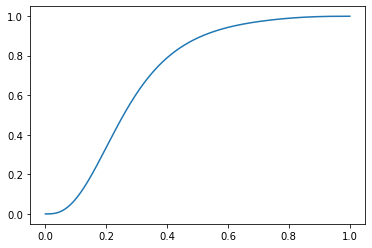

In [10]:
model=dispatch.solar_models.JCD_S(top=top)
M=[]
dM=[]
m=0.0
R_sun=SI.R_sun.cgs.value
M_sun=SI.M_sun.cgs.value
c=4.*np.pi*R_sun**3
M.append(M_sun*0.99905)
for i in range(1,len(model.r)):
    dm=c*(model.rho[i-1]*model.r[i-1]**2+model.rho[i]*model.r[i]**2)*(model.r[i-1]-model.r[i])/2
    dM.append(dm)
    m=m+dm
    M.append(M[0]-m)

M=M
pl.plot(model.r,M/M_sun);

### Acceleration of gravity

log10(g) = 4.44


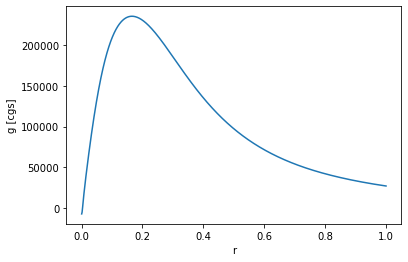

In [11]:
g=SI.G.cgs.value*np.array(M)/(model.r**2+1e-5)/SI.R_sun.cgs.value**2
np.log10(g[0])
pl.plot(model.r,g); pl.xlabel('r'); pl.ylabel('g [cgs]');
print('log10(g) = {:.2f}'.format(np.log10(g[0])))
g0=np.copy(g)
r0=np.copy(model.r)

## Test of forward and reverse EOS lookup

In [12]:
d0=3e-7
T0=6000
P0=np.exp(eos.lookup('ln(P)',np.log(d0),np.log(T0)))
P0/1e5

1.1515108558976375

In [13]:
E0=np.exp(eos.lookup('ln(E)',np.log(d0),np.log(T0)))
np.exp(eos.inverse_lookup('ln(E)',np.log(d0),np.log(E0)))

6000.001956525742

In [14]:
def lookup(v,d,T):
    return np.exp(eos.lookup(v,np.log(d),np.log(T)))
def inverse_lookup(v,d,E):
    return np.exp(eos.inverse_lookup(v,np.log(d),np.log(E)))
T1=6000
d1=3e-7
E1=lookup('ln(E)',d1,T1)
inverse_lookup('ln(E)',d1,E1)

6000.001956525742

## Entropy profile of Model S with Tomida & Hori EOS

1430

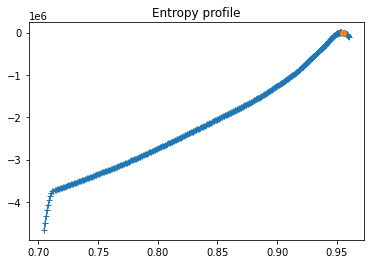

In [15]:
model=dispatch.solar_models.JCD_S(top=top)

S=[]
S.append(0.0)
n=1600
r=model.r[0:n]
R=r*R_sun
d=model.rho[0:n]
T=model.T[0:n]
E=lookup('ln(E)',d,T)
P=lookup('ln(P)',d,T)

for i in range(1,n):
    dlnd=np.log(d[i]/d[i-1])
    Pd=(P[i-1]+P[i])/(d[i-1]+d[i])
    Ta=0.5*(T[i-1]+T[i])
    dE=E[i]-E[i-1]
    S1=S[i-1]+(dE-Pd*dlnd)/Ta
    S.append(S1)

i0=965
S=S-S[i0]
w=np.where((r > 0.704) & (r<0.96))
pl.plot(r[w],S[w],'-+');
pl.plot(r[i0],S[i0],'o');
pl.title('Entropy profile')
w[0][-1]

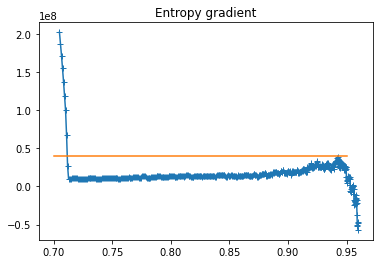

In [16]:
dSdr=np.gradient(S,r)
pl.plot(r[w],dSdr[w],'-+');
dSdr0=4e7
pl.plot([0.7,0.95],[dSdr0,dSdr0])
pl.title('Entropy gradient');

So, 4e7 is a good trigger for leaving the adiabat

## Re-integration of hydrostatic balance, with constant entropy in the CZ below peak entropy

In [17]:
R=r*R_sun
G0=SI.G.cgs.value
c=4*np.pi

print('isentropic from index',i0)
verbose=0
i1=0
if verbose>0:
    n1=i0+4
else:
    n1=len(r)
for i in range(i0+1,n1):
    dlnd=np.log(d[i]/d[i-1])                                                    # step in ln(d) (constant)
    da=(d[i]+d[i-1])/2                                                          # average density (constant)
    g1=G0*M[i-1]/r[i-1]**2                                                      # first guess
    Pd=(P[i-1]+P[i])/(d[i-1]+d[i])                                              # first guess
    dE=Pd*dlnd                                                                  # adiabatic enery increment
    E[i]=E[i-1]+dE                                                              # new internal energy
    M[i]=M[i-1]

    # as long as dSdr stays below the trigger value, enforce constant S
    if dSdr[i] < dSdr0:
        # iterate to constant entropy and exact hydrostatic balance
        for iter in range(1):
            T[i]=inverse_lookup('ln(E)',d[i],E[i])                              # new temperature
            P[i]=lookup('ln(P)',d[i],T[i])                                      # new pressure
            if verbose>2:
                print('{:3d} {:3d} {:14.8f} {:14.5e} {:14.5e} {:14.5e}'.format(i,iter,r[i],d[i],P[i],T[i]))
            Ta=(T[i-1]+T[i])/2                                                  # new average temperature
            if verbose>3: print('Ta',Ta)
            Pd=(P[i-1]+P[i])/(d[i-1]+d[i])                                      # new average P/d
            if verbose>3: print('Pd',Pd)
            dP=P[i]-P[i-1]                                                      # P increment (positive)
            g1=G0*(M[i]/R[i]**2+M[i-1]/R[i-1]**2)/2                             # acc. of gravity
            if verbose>3: print(' g',g)
            if verbose>3: print('da',da)
            dR=-dP/(g1*da)                                                      # radius increment (negative)
            if verbose>3: print('dr',dr)
            R[i]=R[i-1]+dR                                                      # new radius
            dM=c*(d[i-1]*R[i-1]**2+d[i]*R[i]**2)*dR/2                           # dm = change in mass
            M[i]=M[i-1]+dM                                                      # new mass at [i]
            dE=Pd*dlnd                                                          # adiabatic enery increment
            E[i]=E[i-1]+dE                                                      # new internal energy
            if verbose>1:
                print('{:3d} {:3d} {:14.8f} {:14.5e} {:14.5e} {:14.5e}'.format(i,iter,r[i],d[i],P[i],T[i]))
        Sprv=S[i]
        S[i]=S[i-1]
        r[i]=R[i]/R_sun
    # after that, just adjust with the accumulated shift, and recompute
    else:
        if i1==0:
            i1=i
            print('switch to stable layer at index:',i1,' radius:',r[i1])
        S[i]=S[i]-Sprv
        dS=S[i]-S[i-1]                                                          # new dS
        Ta=(T[i-1]+T[i])/2                                                      # average temperature
        # iterate to exact hydrostatic balance
        for iter in range(20):
            dE=Pd*dlnd+dS/Ta                                                    # internal energy incr
            E[i]=E[i-1]+dE                                                      # new internal energy
            T[i]=inverse_lookup('ln(E)',d[i],E[i])                              # new temperature
            P[i]=lookup('ln(P)',d[i],T[i])                                      # new pressure
            Ta=(T[i-1]+T[i])/2                                                  # new average temperature
            Pd=(P[i-1]+P[i])/(d[i-1]+d[i])                                      # new average P/d
            dP=P[i]-P[i-1]                                                      # P increment (positive)
            g1=G0*(M[i]/R[i]**2+M[i-1]/R[i-1]**2)/2                             # acc. of gravity
            dR=-dP/(g1*da)                                                      # radius increment (negative)
            R[i]=R[i-1]+dR                                                      # new radius
            dM=c*(d[i-1]*R[i-1]**2+d[i]*R[i]**2)*dR/2                           # dm = change in mass
            M[i]=M[i-1]+dM                                                      # new mass at [i]
            if verbose>1:
                print('{:3d} {:3d} {:14.8f} {:14.5e} {:14.5e} {:14.5e}'.format(i,iter,r[i],d[i],P[i],T[i]))

    r[i]=R[i]/R_sun
    g[i]=G0*M[i]/R[i]**2
    if verbose > 0:
        print(i,r[i],S[i])
        #print(i,r[i],S[i])
print('new bottom radius:',r[-1])

isentropic from index 965
switch to stable layer at index: 1423  radius: 0.7109138
new bottom radius: 0.4502151350725955


### Entropy profile below CZ

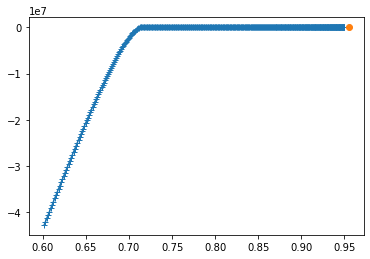

In [18]:
w=np.where((r < 0.95) & (r > 0.60))
pl.plot(r[w],S[w],'-+');
pl.plot(r[i0],S[i0],'o');

In [19]:
### New mass profile

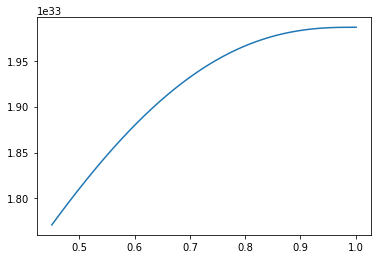

In [20]:
pl.plot(r,M[0:len(r)]);

#### New acceleration of gravity profile

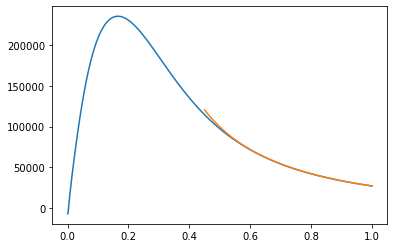

In [21]:
pl.plot(r0,g0);
pl.plot(r,g[0:len(r)]);

## Write out .tbl file for DISPATCH, in CGS units

In [22]:
n=len(r)
idx=[0.1,5]
file='JCD-model-S.tbl'
with open(file,'w') as fd:
    fd.write('{} {}\n'.format(n,len(idx)))
    for i in range(n):
        line='{:12.8f} {:18.8e} {:18.8e} {:18.8e}\n'.format(r[i],g[i],d[i],E[i])
        fd.write(line)